In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import LSTM, Dropout, Dense, Bidirectional, BatchNormalization
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.metrics import BinaryAccuracy, AUC
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import random

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\tensorflow\python\keras\engine\training_arrays_v1.py:37: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 1.23.2)
  from scipy.sparse import issparse  # pylint: disable=g-import-not-at-top


In [2]:
# Set seed for reproducibility
seed = 42
np.random.seed(seed)
tf.random.set_seed(seed)
random.seed(seed)

In [3]:
# Load the dataset
data_x = pd.read_csv('X_hml8.csv')
data_y = pd.read_csv('y_hml8.csv')

In [4]:
# Remove the 'Unnamed: 0' column if it exists
if 'Unnamed: 0' in data_x.columns:
    data_x = data_x.drop(columns=['Unnamed: 0'])
if 'Unnamed: 0' in data_y.columns:
    data_y = data_y.drop(columns=['Unnamed: 0'])

In [5]:
# Feature selection
columns_to_keep = list(data_x.columns[:6]) + [
    'EMA_25_mkt', 'SMA_100_cma', 'EMA_26_rmw', 'EMA_25_smb',
    'EMA_25_umd', 'EMA_12_cma', 'RSI_9_cma', 'EMA_26_hml',
    'RSI_9_rmw', 'RSI_9_mkt', 'RSI_9_smb', 'RSI_14_hml'
]

X_train = data_x[columns_to_keep]
y_train = data_y['Target']

In [6]:
# Convert to numpy arrays
X = X_train.values
y = y_train.values

In [7]:
# Use StandardScaler to scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [8]:
# Convert back to DataFrame for EDA
X_scaled_df = pd.DataFrame(X_scaled, columns=columns_to_keep)

In [9]:
# Perform EDA on the final input matrix
X_scaled_df.describe().T

,count,mean,std,min,25%,50%,75%,max
RET_cma,2129.0,-8.760802e-18,1.000235,-8.293726,-0.517883,-0.006036,0.525959,7.933323
RET_hml,2129.0,6.674897e-18,1.000235,-3.887676,-0.611578,-0.033145,0.587042,4.753445
RET_mkt,2129.0,2.336214e-17,1.000235,-11.363081,-0.448243,0.018535,0.479991,8.588009
RET_rmw,2129.0,1.168107e-17,1.000235,-5.501667,-0.596083,0.006557,0.610159,5.115630
RET_smb,2129.0,0.000000e+00,1.000235,-8.440059,-0.494293,0.030894,0.573561,6.091110
RET_umd,2129.0,-2.085905e-18,1.000235,-13.256709,-0.516088,-0.003167,0.519158,7.499463
EMA_25_mkt,2129.0,1.174782e-15,1.000235,-2.292113,-0.798175,0.276070,0.832795,1.495881
SMA_100_cma,2129.0,7.475884e-16,1.000235,-1.276413,-0.977475,-0.305629,0.709515,2.710751
EMA_26_rmw,2129.0,-1.922370e-15,1.000235,-2.421149,-0.617095,-0.129423,0.472417,3.368184
EMA_25_smb,2129.0,-8.009876e-17,1.000235,-1.976555,-0.907582,0.492530,0.805121,1.280829


In [10]:
# Class weight function
def cwts(dfs):
    c0, c1 = np.bincount(dfs)
    w0 = (1/c0) * (len(dfs)) / 2 
    w1 = (1/c1) * (len(dfs)) / 2 
    return {0: w0, 1: w1}


In [11]:
# Check class frequency
c = np.bincount(y_train)
c

array([ 711, 1418], dtype=int64)

In [12]:
# Define sliding window parameters
window_size = 600
test_gap = 180
step_size = 1

In [13]:
# Determine the start point to process only the last 500 windows
start_point = len(X) - (500 * step_size) - window_size - test_gap

In [14]:
# Lists to store results
all_test_predictions = []
all_actual_test_values = []
all_prediction_probabilities = []
all_predicted_classes = []
all_predicted_probabilities = []

In [15]:
# Define model creation function
def create_model(hu=20, lookback=10, features=1):
    tf.keras.backend.clear_session()
    model = Sequential()
    model.add(LSTM(units=hu, input_shape=(lookback, features), activation='relu', return_sequences=True, name='LSTM1'))
    model.add(Dropout(0.4, name='Dropout1'))
    model.add(LSTM(units=hu, activation='relu', return_sequences=False, name='LSTM2'))
    model.add(Dropout(0.2, name='Dropout2'))
    model.add(Dense(units=1, activation='sigmoid', name='Output'))
    opt = Adam(learning_rate=0.001, epsilon=1e-08, decay=0.0)
    model.compile(optimizer=opt, 
                  loss=BinaryCrossentropy(), 
                  metrics=[BinaryAccuracy(name='accuracy', threshold=0.5), AUC()])
    return model

In [16]:
# EarlyStopping and ReduceLROnPlateau callbacks
early_stopping = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='loss', factor=0.2, patience=5, min_lr=0.0001)

In [17]:
# Train and evaluate the model with sliding window
for start in range(start_point, len(X_scaled) - window_size - test_gap, step_size):
    try:
        end = start + window_size
        X_train_window = X_scaled[start:end]
        y_train_window = y[start:end]
        
        # Define test indices
        test_start = end + test_gap
        test_end = test_start + 1
        if test_end > len(X_scaled):
            break
        X_test_window = X_scaled[test_start:test_end]
        y_test_window = y[test_start:test_end]

        # Sequence length for training
        seqlen = 10
        # Number of features
        numfeat = X_train_window.shape[1]

        # Generate sequence input for the training dataset
        train_generator = TimeseriesGenerator(X_train_window, y_train_window, length=seqlen, batch_size=64)

        # Calculate custom class weights using y_train_window
        class_weight = cwts(y_train_window)

        # Create a new model for each window
        model = create_model(hu=20, lookback=10, features=numfeat)
        model.compile(loss=BinaryCrossentropy(), optimizer=SGD(learning_rate=1e-3), metrics=[BinaryAccuracy(name='accuracy', threshold=0.5), AUC()])

        model.fit(train_generator, epochs=74, verbose=1, class_weight=class_weight, shuffle=False, callbacks=[early_stopping, reduce_lr])

        
        # Predict on the single test sample directly
        test_input = np.expand_dims(X_test_window, axis=0)
        prediction = model.predict(test_input)
        prediction_probability = prediction[0][0]
        predicted_class = int(prediction_probability > 0.5)
        print(f'Test Prediction: {prediction_probability:.2f} (Class: {predicted_class})')

        # Store test predictions, actual values, and predicted classes
        all_test_predictions.append(predicted_class)
        all_actual_test_values.append(y_test_window[0])
        all_prediction_probabilities.append(prediction_probability)
        all_predicted_classes.append(predicted_class)
        all_predicted_probabilities.append(prediction_probability)

        # Predict on the training set
        y_pred_train_probs = model.predict(train_generator)
        y_pred_train = (y_pred_train_probs > 0.5).astype(int)

        # Calculate and print confusion matrix
        cm = confusion_matrix([y_test_window[0]], [predicted_class])

    except Exception as e:
        print(f'Error at window {start} to {end}: {e}')
        break



Epoch 1/74


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.3852 - auc_1: 0.4033 - loss: 0.7069 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4592 - auc_1: 0.4537 - loss: 0.7032 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4210 - auc_1: 0.4310 - loss: 0.7043 - learning_rate: 0.0010


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4363 - auc_1: 0.4537 - loss: 0.7027 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4237 - auc_1: 0.4334 - loss: 0.7043 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4510 - auc_1: 0.4679 - loss: 0.7024 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4393 - auc_1: 0.4568 - loss: 0.7037 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4228 - auc_1: 0.4314 - loss: 0.7042 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4246 - auc_1: 0.4461 - loss: 0.7034 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4473 - auc_1: 0.4650 - loss: 0.7029 - learning_rate: 0.0010
Epoch 11/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3886 - auc_1: 0.4065 - loss: 0.7055 - learning_rate: 0.0010
Epoch 

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


... (2,403 outputs left out)

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4124 - auc_1: 0.4724 - loss: 0.6721 - learning_rate: 0.0010
Epoch 2/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4276 - auc_1: 0.5272 - loss: 0.6677 - learning_rate: 0.0010
Epoch 3/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4016 - auc_1: 0.5142 - loss: 0.6701 - learning_rate: 0.0010


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 4/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4169 - auc_1: 0.5132 - loss: 0.6681 - learning_rate: 0.0010
Epoch 5/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4359 - auc_1: 0.5375 - loss: 0.6656 - learning_rate: 0.0010
Epoch 6/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4258 - auc_1: 0.4996 - loss: 0.6703 - learning_rate: 0.0010
Epoch 7/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4488 - auc_1: 0.4727 - loss: 0.6672 - learning_rate: 0.0010
Epoch 8/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4068 - auc_1: 0.5088 - loss: 0.6700 - learning_rate: 0.0010
Epoch 9/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4538 - auc_1: 0.5077 - loss: 0.6673 - learning_rate: 0.0010
Epoch 10/74
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4315 - auc_1: 0.4968 - loss: 0.6678 - learning_rate: 0.0010
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
Test Prediction: 0.50 (Class: 0)
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


In [18]:
# Save the results to files for further analysis
# Save the results to files for further analysis
results = {
    "predicted_classes": all_test_predictions,
    "actual_test_values": all_actual_test_values,
    "prediction_probabilities": all_prediction_probabilities,
    "predicted_probabilities": all_predicted_probabilities
}
results_df = pd.DataFrame(results)
results_df.to_csv('SL_results_HML.csv', index=False)

In [19]:
# Generate and print the combined classification report
combined_classification_report = classification_report(all_actual_test_values, all_predicted_classes, output_dict=True)
print("Combined Classification Report:")
print(combined_classification_report)

Combined Classification Report:
{'0': {'precision': 0.5451127819548872, 'recall': 0.5141843971631206, 'f1-score': 0.5291970802919708, 'support': 282.0}, '1': {'precision': 0.41452991452991456, 'recall': 0.44495412844036697, 'f1-score': 0.42920353982300885, 'support': 218.0}, 'accuracy': 0.484, 'macro avg': {'precision': 0.47982134824240086, 'recall': 0.4795692628017438, 'f1-score': 0.4792003100574898, 'support': 500.0}, 'weighted avg': {'precision': 0.4881786517575991, 'recall': 0.484, 'f1-score': 0.4855998966475033, 'support': 500.0}}


In [20]:
# Calculate and print the combined confusion matrix
combined_cm = confusion_matrix(all_actual_test_values, all_predicted_classes)
print(f'Combined Confusion Matrix:\n{combined_cm}')


Combined Confusion Matrix:
[[145 137]
 [121  97]]


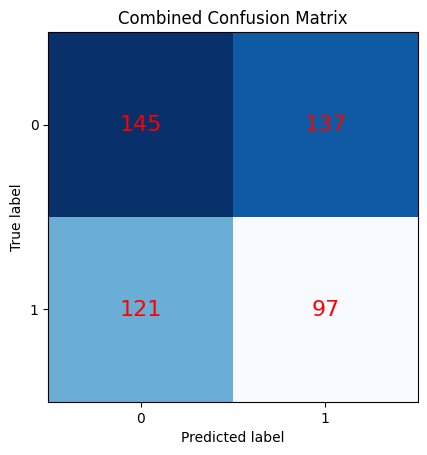

In [21]:
# Plot the combined confusion matrix
fig, ax = plt.subplots()
ax.imshow(combined_cm, cmap=plt.cm.Blues)
ax.grid(False)

for i in range(combined_cm.shape[0]):  # Add number annotations for each cell
    for j in range(combined_cm.shape[1]):
        ax.text(j, i, combined_cm[i, j], ha="center", va="center", color="red", fontsize=16)

plt.title('Combined Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.xticks(np.arange(2), [0, 1])
plt.yticks(np.arange(2), [0, 1])

plt.show()

In [22]:
# Save the final model
model.save('SL_model_HML8.h5')